# Part 2: Logistic Regression and Decision Tree

This notebook implements and evaluates Logistic Regression
and Decision Tree classifiers for spam email detection.

## 1. Imports and Data Loading

In [23]:
import sys
from pathlib import Path

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

sys.path.insert(0, str(root))

import pandas as pd
import matplotlib.pyplot as plt

from src.data import get_train_test

X_train, X_test, y_train, y_test = get_train_test()

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (3368, 57)
Testing: (842, 57)


## 2. Model Implementation and Training

In [24]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=42)
)

tree_model = DecisionTreeClassifier(
    random_state=42
)

logistic_model.fit(X_train, y_train)
tree_model.fit(X_train, y_train)

print("Both models trained successfully!")

Both models trained successfully!


## Decision Tree Hyperparameter Tuning

In [25]:
from sklearn.model_selection import GridSearchCV

# Test different Decision Tree settings
parameters = {
    "max_depth": [3, 5, 10, 15, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5]
}

grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    parameters,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

# Replace original Decision Tree with tuned model
tree_model = grid_search.best_estimator_

print("Best parameters:", grid_search.best_params_)
print("Best CV F1 score:", grid_search.best_score_)

Best parameters: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 10}
Best CV F1 score: 0.8918286212351971


## 3. Model Performance Evaluation

In [26]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": tree_model
}

results = []

for name, model in models.items():
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1": f1_score(y_test, predictions),
        "ROC AUC": roc_auc_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results)

print(results_df.round(4))

                 Model  Accuracy  Precision  Recall      F1  ROC AUC
0  Logistic Regression    0.9347     0.9297  0.9048  0.9170   0.9768
1        Decision Tree    0.9086     0.8936  0.8750  0.8842   0.9221


## 4. Confusion Matrix Analysis

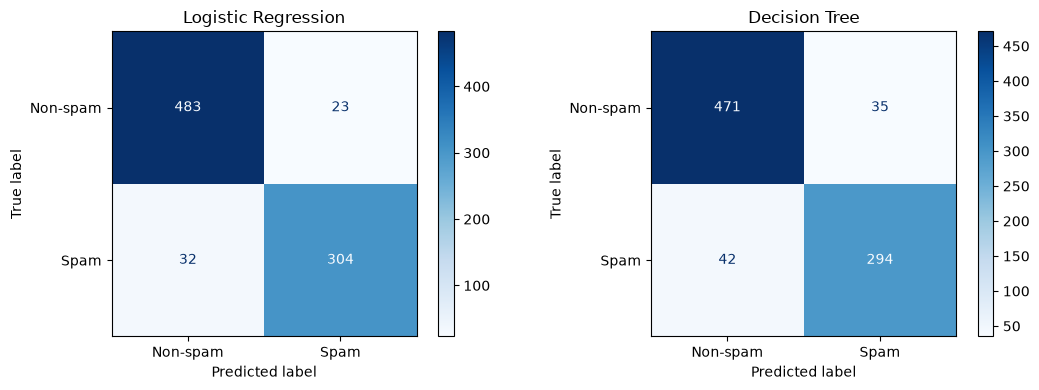

In [27]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model,
        X_test,
        y_test,
        ax=ax,
        cmap="Blues",
        display_labels=["Non-spam", "Spam"]
    )
    ax.set_title(name)

plt.tight_layout()
plt.savefig(root / "figures" / "02_confusion_matrices.png")
plt.show()

## 5. Model Performance Comparison

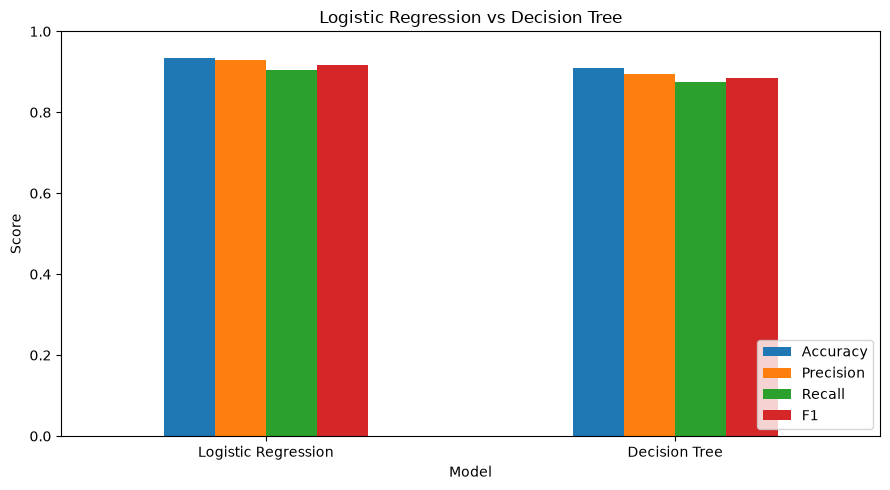

In [28]:
results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1"]
].plot(kind="bar", figsize=(9, 5), rot=0)

plt.title("Logistic Regression vs Decision Tree")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(root / "figures" / "02_model_comparison.png")
plt.show()

## 6. Save Evaluation Results

In [29]:
results_df.to_csv(
    root / "results" / "02_model_metrics.csv",
    index=False
)

print("Results saved successfully!")

Results saved successfully!


## 7. Model Selection and Justification

# Logistic Regression

Chosen as a simple, interpretable baseline for binary classification. It predicts the probability that an email is spam using a weighted combination of features.

# Decision Tree

Chosen because it learns nonlinear decision rules and can capture interactions between features. Unlike Logistic Regression, it doesn't require feature scaling.

# Comparison

Logistic Regression is generally simpler and less prone to overfitting, while an unrestricted Decision Tree can fit complex patterns but may overfit training data.

# Decision Tree Tuning

GridSearchCV was used with 5-fold cross-validation to
identify the best Decision Tree hyperparameters.

The model was optimized using F1-score to balance
precision and recall when classifying spam emails.

Hyperparameter tuning helps control overfitting and
improve performance on unseen data.